<a href="https://colab.research.google.com/github/nidomarinho-Tito/projeto-ananas-ml/blob/main/Projeto_Ananas_Abacaxi_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## STEC- Carreira Tech - Trilha Inteligência Artificial
# Machine Learning Preditivo com Python
# Aluno: Nivaldo Marinho

# Projeto Avaliativo: API Preditiva de Cultivares de Abacaxi (*Ananas comosus*)
**Opção B — Pipeline de Machine Learning e Microsserviço FastAPI Modular**

Este notebook constrói passo a passo toda a estrutura modular do projeto, gerando os pacotes Python (`app/`, `scripts/`, `data/`, `models/`), treinando o modelo e validando os endpoints HTTP.

## Etapa 1: Instalação das Bibliotecas e Criação das Pastas do Projeto
Nesta primeira etapa, instalamos o FastAPI, Uvicorn, Pydantic e HTTPX (para testes de requisição no Colab) e criamos a árvore de diretórios exigida pela arquitetura modular.

In [113]:
from pathlib import Path
import sys
import subprocess

# Uma única lista de dependências para o notebook e para a execução local.
Path("requirements.txt").write_text("""fastapi>=0.115,<1
uvicorn>=0.30,<1
pydantic>=2.9,<3
scikit-learn>=1.5,<2
pandas>=2.2,<3
numpy>=1.26,<3
joblib>=1.4,<2
httpx>=0.27,<1
matplotlib>=3.8,<4
seaborn>=0.13,<1
""", encoding="utf-8")
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"])
for folder in ("data", "models", "app", "scripts", "tests"):
    Path(folder).mkdir(parents=True, exist_ok=True)
Path("app/__init__.py").write_text('"""API de classificação de cultivares de abacaxi."""\n', encoding="utf-8")
print("Dependências e diretórios preparados.")


Dependências e diretórios preparados.


## Etapa 2 — Base sintética e rastreabilidade científica

**Escopo:** os 1.200 registros são simulados e não correspondem a medições publicadas ou experimentos de campo. As médias, os desvios-padrão e as probabilidades categóricas abaixo são **hipóteses didáticas**, não parâmetros oficiais de cultivares. A distribuição é artificialmente equilibrada entre as cinco classes.

A Embrapa e o MAPA são fontes de consulta sobre cultivares e descritores, **não fontes dos números gerados**. A classificação e as recomendações agronômicas não devem ser utilizadas para decisões comerciais ou fitossanitárias sem validação com dados reais e especialistas.


### Fontes para conferência e limites de evidência

- [Embrapa Mandioca e Fruticultura](https://www.embrapa.br/mandioca-e-fruticultura): consultar materiais específicos sobre a cultura, características de cultivares e resistência à fusariose.
- [Busca de publicações da Embrapa](https://www.embrapa.br/busca-de-publicacoes): localizar boletins técnicos por nome de cultivar, autor, título e ano; conferir a descrição original antes de atribuir características.
- [Registro Nacional de Cultivares — MAPA](https://www.gov.br/agricultura/pt-br/assuntos/insumos-agricolas/sementes-e-mudas/registro-nacional-de-cultivares-rnc): consultar informações de registro, que **não** substituem medições morfoagronômicas.

**Rastreabilidade:** `data/proveniencia_base.md` registra a origem de cada grupo de variáveis, a metodologia de simulação e os limites do catálogo. Não foram obtidas nem verificadas tabelas numéricas primárias nesta revisão; portanto, não se atribuem os parâmetros simulados a órgãos oficiais.


In [114]:
import numpy as np
import pandas as pd
from pathlib import Path

rng = np.random.default_rng(42)
n_samples_per_class = 240

profiles = {
    "Perola": {
        "massa_fruto_g": (1350, 180),
        "comprimento_fruto_cm": (19.5, 1.8),
        "diametro_fruto_cm": (11.2, 0.9),
        "diametro_cilindro_mm": (21.0, 2.5),
        "brix_sst": (14.2, 1.1),
        "acidez_titulavel_pct": (0.48, 0.08),
        "firmeza_polpa_n": (16.5, 2.0),
        "cor_polpa": ["branca", "amarelo_palido"],
        "cor_polpa_probs": [0.85, 0.15],
        "presenca_espinhos": ["presente", "ausente"],
        "espinhos_probs": [0.95, 0.05],
        "formato_fruto": ["conico", "cilindrico"],
        "formato_probs": [0.90, 0.10]
    },
    "Smooth_Cayenne": {
        "massa_fruto_g": (1850, 240),
        "comprimento_fruto_cm": (17.8, 1.6),
        "diametro_fruto_cm": (13.4, 1.0),
        "diametro_cilindro_mm": (26.5, 3.0),
        "brix_sst": (15.1, 1.2),
        "acidez_titulavel_pct": (0.72, 0.11),
        "firmeza_polpa_n": (19.2, 2.2),
        "cor_polpa": ["amarelo_palido", "amarela"],
        "cor_polpa_probs": [0.65, 0.35],
        "presenca_espinhos": ["ausente", "presente"],
        "espinhos_probs": [0.88, 0.12],
        "formato_fruto": ["cilindrico", "conico"],
        "formato_probs": [0.85, 0.15]
    },
    "BRS_Imperial": {
        "massa_fruto_g": (1480, 170),
        "comprimento_fruto_cm": (16.2, 1.5),
        "diametro_fruto_cm": (12.1, 0.8),
        "diametro_cilindro_mm": (18.5, 2.2),
        "brix_sst": (17.6, 1.1),
        "acidez_titulavel_pct": (0.52, 0.07),
        "firmeza_polpa_n": (20.5, 1.9),
        "cor_polpa": ["amarelo_ouro", "amarela"],
        "cor_polpa_probs": [0.82, 0.18],
        "presenca_espinhos": ["ausente", "presente"],
        "espinhos_probs": [0.98, 0.02],
        "formato_fruto": ["cilindrico", "conico"],
        "formato_probs": [0.92, 0.08]
    },
    "BRS_Vitoria": {
        "massa_fruto_g": (1420, 165),
        "comprimento_fruto_cm": (17.0, 1.5),
        "diametro_fruto_cm": (11.8, 0.9),
        "diametro_cilindro_mm": (19.8, 2.3),
        "brix_sst": (15.8, 1.0),
        "acidez_titulavel_pct": (0.64, 0.09),
        "firmeza_polpa_n": (18.8, 2.1),
        "cor_polpa": ["branca", "amarelo_palido"],
        "cor_polpa_probs": [0.90, 0.10],
        "presenca_espinhos": ["ausente", "presente"],
        "espinhos_probs": [0.97, 0.03],
        "formato_fruto": ["cilindrico", "conico"],
        "formato_probs": [0.88, 0.12]
    },
    "MD2_Gold": {
        "massa_fruto_g": (1720, 210),
        "comprimento_fruto_cm": (17.5, 1.5),
        "diametro_fruto_cm": (13.0, 0.9),
        "diametro_cilindro_mm": (23.0, 2.5),
        "brix_sst": (16.4, 1.1),
        "acidez_titulavel_pct": (0.45, 0.07),
        "firmeza_polpa_n": (22.4, 2.0),
        "cor_polpa": ["amarelo_ouro", "amarela"],
        "cor_polpa_probs": [0.75, 0.25],
        "presenca_espinhos": ["ausente", "presente"],
        "espinhos_probs": [0.92, 0.08],
        "formato_fruto": ["cilindrico", "conico"],
        "formato_probs": [0.94, 0.06]
    }
}

rows = []
for cultivar, p in profiles.items():
    for _ in range(n_samples_per_class):
        rows.append({
            "massa_fruto_g": round(float(np.clip(rng.normal(*p["massa_fruto_g"]), 550, 3800)), 1),
            "comprimento_fruto_cm": round(float(np.clip(rng.normal(*p["comprimento_fruto_cm"]), 10.0, 28.0)), 2),
            "diametro_fruto_cm": round(float(np.clip(rng.normal(*p["diametro_fruto_cm"]), 8.0, 18.0)), 2),
            "diametro_cilindro_mm": round(float(np.clip(rng.normal(*p["diametro_cilindro_mm"]), 10.0, 42.0)), 2),
            "brix_sst": round(float(np.clip(rng.normal(*p["brix_sst"]), 9.5, 22.0)), 2),
            "acidez_titulavel_pct": round(float(np.clip(rng.normal(*p["acidez_titulavel_pct"]), 0.22, 1.40)), 3),
            "firmeza_polpa_n": round(float(np.clip(rng.normal(*p["firmeza_polpa_n"]), 10.0, 30.0)), 2),
            "cor_polpa": rng.choice(p["cor_polpa"], p=p["cor_polpa_probs"]),
            "presenca_espinhos": rng.choice(p["presenca_espinhos"], p=p["espinhos_probs"]),
            "formato_fruto": rng.choice(p["formato_fruto"], p=p["formato_probs"]),
            "cultivar": cultivar
        })

df = pd.DataFrame(rows)
missing_rng = np.random.default_rng(123)
for col in ["massa_fruto_g", "diametro_cilindro_mm", "firmeza_polpa_n", "cor_polpa"]:
    mask = missing_rng.random(len(df)) < 0.02
    df.loc[mask, col] = np.nan

csv_path = Path("data/ananas_comosus_cultivares.csv")
csv_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(csv_path, index=False)
print(f"Base salva em {csv_path} com {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head()
Path("data/proveniencia_base.md").write_text("""# Proveniência da base Ananas

- Tipo: base inteiramente sintética para demonstração de software.
- Classes: Perola, Smooth_Cayenne, BRS_Imperial, BRS_Vitoria, MD2_Gold.
- Variáveis numéricas: massa, comprimento, diâmetros, sólidos solúveis, acidez e firmeza; unidades nos nomes das colunas.
- Variáveis categóricas: cor da polpa, espinhos e formato.
- Parâmetros de distribuição: médias, desvios e probabilidades definidos manualmente no notebook; **não derivados de medições oficiais**.
- Método: gerador NumPy com semente 42, 240 amostras por classe, truncamento de valores e ausências artificiais de aproximadamente 2% em quatro colunas com semente 123.
- Referências de contexto: https://www.embrapa.br/mandioca-e-fruticultura ; https://www.embrapa.br/busca-de-publicacoes ; https://www.gov.br/agricultura/pt-br/assuntos/insumos-agricolas/sementes-e-mudas/registro-nacional-de-cultivares-rnc
- Limitação: as fontes são pontos de consulta; não foi verificada uma tabela primária que sustente cada parâmetro numérico ou cada afirmação do catálogo.
- Uso: apenas ensino, testes de integração e demonstração. Não validado em campo.
""", encoding="utf-8")


Base salva em data/ananas_comosus_cultivares.csv com 1200 linhas e 11 colunas.


1133

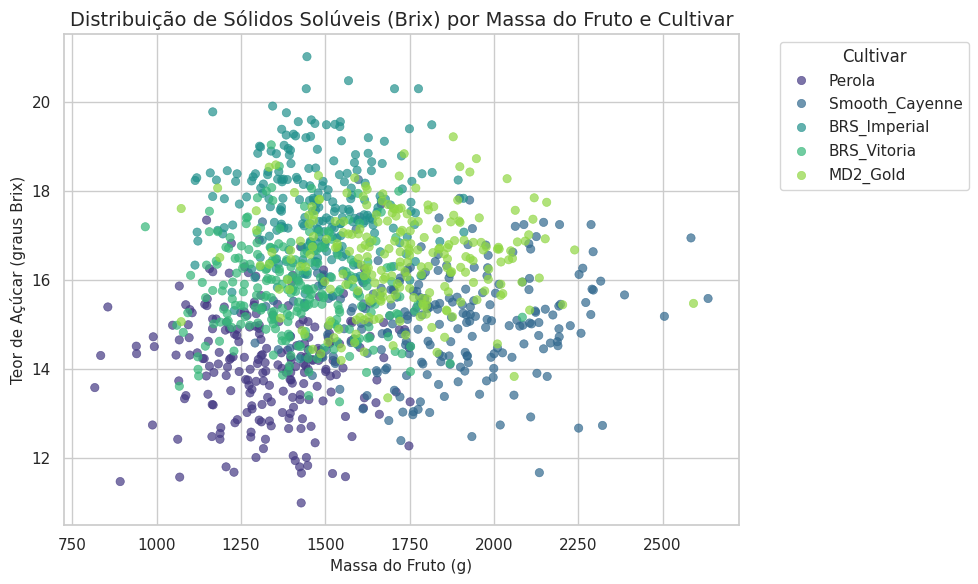

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configura o estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Cria o gráfico de dispersão (Scatter Plot)
sns.scatterplot(
    data=df,
    x="massa_fruto_g",
    y="brix_sst",
    hue="cultivar",
    palette="viridis",
    alpha=0.7,
    edgecolor=None
)

plt.title("Distribuição de Sólidos Solúveis (Brix) por Massa do Fruto e Cultivar", fontsize=14)
plt.xlabel("Massa do Fruto (g)", fontsize=11)
plt.ylabel("Teor de Açúcar (graus Brix)", fontsize=11)
plt.legend(title="Cultivar", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Etapa 3 (Fase 1): Preparação, Treinamento e Serialização do Modelo (`scripts/train_pipeline.py`)
Usamos o comando `%%writefile` para gravar o script Python real na pasta `scripts/` e, na célula seguinte, executamos o treinamento para gerar o artefato `models/pipeline_ananas_v1.joblib` e o relatório `models/metrics_report.json`.

In [116]:
%%writefile scripts/train_pipeline.py
"""
Fase 1: Preparacao, Treinamento e Serializacao do Pipeline Preditivo (Offline)
Projeto: Classificacao Morfoagronomica de Cultivares de Abacaxi (Ananas comosus L. Merril)
"""

import json
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, log_loss, confusion_matrix
import joblib

BASE_DIR = Path(__file__).resolve().parent.parent
DATA_PATH = BASE_DIR / "data" / "ananas_comosus_cultivares.csv"
MODEL_PATH = BASE_DIR / "models" / "pipeline_ananas_v1.joblib"
METRICS_PATH = BASE_DIR / "models" / "metrics_report.json"
TEST_INDICES_PATH = BASE_DIR / "models" / "test_indices.json"

NUMERIC_FEATURES = [
    "massa_fruto_g",
    "comprimento_fruto_cm",
    "diametro_fruto_cm",
    "diametro_cilindro_mm",
    "brix_sst",
    "acidez_titulavel_pct",
    "firmeza_polpa_n",
]

CATEGORICAL_FEATURES = [
    "cor_polpa",
    "presenca_espinhos",
    "formato_fruto",
]

TARGET_COL = "cultivar"


def build_pipeline() -> Pipeline:
    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, NUMERIC_FEATURES),
            ("cat", categorical_transformer, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
    )

    classifier = RandomForestClassifier(
        n_estimators=250,
        max_depth=12,
        min_samples_split=4,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )

    return Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier),
        ]
    )


def main() -> None:
    if not DATA_PATH.is_file():
        raise FileNotFoundError(f"Base não encontrada: {DATA_PATH}")
    df = pd.read_csv(DATA_PATH)
    required = set(NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET_COL])
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"Colunas ausentes na base: {sorted(missing)}")
    X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
    y = df[TARGET_COL]

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=42
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
    )

    pipeline = build_pipeline()
    pipeline.fit(X_train, y_train)
    # O conjunto de teste permanece isolado até a avaliação final.

    val_preds = pipeline.predict(X_val)
    val_probs = pipeline.predict_proba(X_val)
    test_preds = pipeline.predict(X_test)
    test_probs = pipeline.predict_proba(X_test)

    # A validação é apenas diagnóstica: hiperparâmetros fixados previamente,
    # sem busca automática nem seleção baseada no conjunto de teste.
    # Probabilidades não calibradas não são garantia de confiança em campo.
    metrics = {
        "model_version": "1.0.0",
        "dataset_origin": "synthetic_demonstration",
        "scientific_limitation": "Métricas sobre dados simulados; não validado em campo.",
        "algorithm": "RandomForestClassifier",
        "dataset_splits": {
            "train_samples": len(X_train),
            "validation_samples": len(X_val),
            "test_samples": len(X_test),
        },
        "validation_metrics": {
            "accuracy": round(float(accuracy_score(y_val, val_preds)), 4),
            "f1_macro": round(float(f1_score(y_val, val_preds, average="macro")), 4),
            "roc_auc_ovr": round(float(roc_auc_score(y_val, val_probs, multi_class="ovr", average="macro")), 4),
        },
        "test_metrics": {
            "accuracy": round(float(accuracy_score(y_test, test_preds)), 4),
            "f1_macro": round(float(f1_score(y_test, test_preds, average="macro")), 4),
            "roc_auc_ovr": round(float(roc_auc_score(y_test, test_probs, multi_class="ovr", average="macro")), 4),
        },
        "classes": list(pipeline.classes_),
        "hyperparameter_selection": "Valores fixados previamente; não houve tuning por validação.",
        "probability_interpretation": "Estimativas não calibradas em dados sintéticos; não representam confiança em campo.",
        "validation_log_loss": round(float(log_loss(y_val, val_probs, labels=pipeline.classes_)), 4),
        "test_confusion_matrix": confusion_matrix(y_test, test_preds, labels=pipeline.classes_).tolist(),
    }

    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    # Índices do teste isolado: reutilizados sem refazer o split ou excluir nulos.
    TEST_INDICES_PATH.write_text(json.dumps([int(i) for i in X_test.index]), encoding="utf-8")
    joblib.dump(pipeline, MODEL_PATH)
    with open(METRICS_PATH, "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=4, ensure_ascii=False)

    print("=== RELATORIO DE TREINAMENTO E SERIALIZACAO ===")
    print(json.dumps(metrics, indent=2, ensure_ascii=False))
    print("\nRelatorio Detalhado (Conjunto de Teste):")
    print(classification_report(y_test, test_preds))


if __name__ == "__main__":
    main()

Overwriting scripts/train_pipeline.py


In [117]:
!python scripts/train_pipeline.py

=== RELATORIO DE TREINAMENTO E SERIALIZACAO ===
{
  "model_version": "1.0.0",
  "dataset_origin": "synthetic_demonstration",
  "scientific_limitation": "Métricas sobre dados simulados; não validado em campo.",
  "algorithm": "RandomForestClassifier",
  "dataset_splits": {
    "train_samples": 840,
    "validation_samples": 180,
    "test_samples": 180
  },
  "validation_metrics": {
    "accuracy": 0.9333,
    "f1_macro": 0.9335,
    "roc_auc_ovr": 0.9906
  },
  "test_metrics": {
    "accuracy": 0.9389,
    "f1_macro": 0.9388,
    "roc_auc_ovr": 0.9958
  },
  "classes": [
    "BRS_Imperial",
    "BRS_Vitoria",
    "MD2_Gold",
    "Perola",
    "Smooth_Cayenne"
  ],
  "hyperparameter_selection": "Valores fixados previamente; não houve tuning por validação.",
  "probability_interpretation": "Estimativas não calibradas em dados sintéticos; não representam confiança em campo.",
  "validation_log_loss": 0.2749,
  "test_confusion_matrix": [
    [
      32,
      2,
      2,
      0,
      0
 

In [118]:
import json
import pandas as pd
from IPython.display import display, Markdown

# Carrega as métricas salvas no arquivo oficial do projeto
with open("models/metrics_report.json", "r", encoding="utf-8") as f:
    metrics = json.load(f)

# Formata e exibe um relatório em Markdown
report_md = f"""
### 📊 Desempenho do Modelo de Machine Learning ({metrics['algorithm']})

- **Acurácia Geral de Teste (Accuracy):** {metrics['test_metrics']['accuracy'] * 100:.2f}%
- **F1-Score Macro (Test):** {metrics['test_metrics']['f1_macro'] * 100:.2f}%
- **Área Sob a Curva ROC (ROC-AUC OVR):** {metrics['test_metrics']['roc_auc_ovr'] * 100:.2f}%

---
**Divisão das Amostras:**
- Treinamento: `{metrics['dataset_splits']['train_samples']}` amostras
- Validação: `{metrics['dataset_splits']['validation_samples']}` amostras
- Teste: `{metrics['dataset_splits']['test_samples']}` amostras

*Nota Científica:* {metrics['scientific_limitation']}
"""

display(Markdown(report_md))


### 📊 Desempenho do Modelo de Machine Learning (RandomForestClassifier)

- **Acurácia Geral de Teste (Accuracy):** 93.89%
- **F1-Score Macro (Test):** 93.88%
- **Área Sob a Curva ROC (ROC-AUC OVR):** 99.58%

---
**Divisão das Amostras:**
- Treinamento: `840` amostras
- Validação: `180` amostras
- Teste: `180` amostras

*Nota Científica:* Métricas sobre dados simulados; não validado em campo.


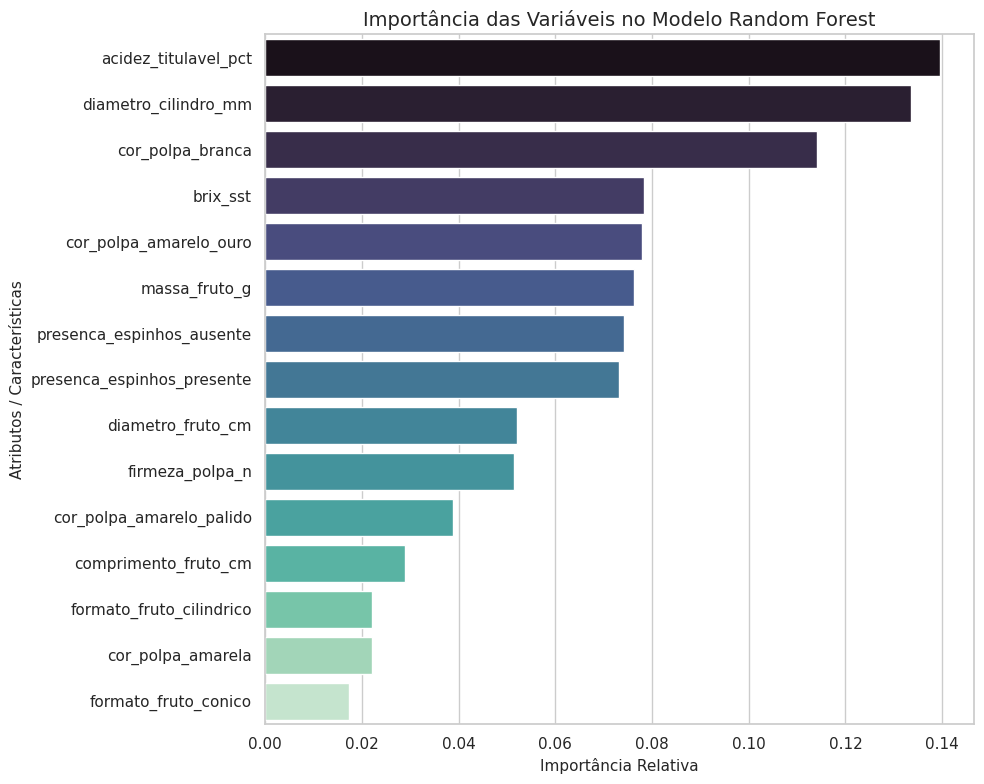

In [119]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregar o pipeline treinado
pipeline_path = "models/pipeline_ananas_v1.joblib"
pipeline = joblib.load(pipeline_path)

# 2. Extrair o pré-processador e o classificador
preprocessor = pipeline.named_steps["preprocessor"]
classifier = pipeline.named_steps["classifier"]

# 3. Mapear os nomes das colunas geradas pelo ColumnTransformer
# Colunas numéricas mantêm o nome original
num_features = [
    "massa_fruto_g",
    "comprimento_fruto_cm",
    "diametro_fruto_cm",
    "diametro_cilindro_mm",
    "brix_sst",
    "acidez_titulavel_pct",
    "firmeza_polpa_n",
]

# Colunas categóricas passam pelo OneHotEncoder
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
cat_features_raw = ["cor_polpa", "presenca_espinhos", "formato_fruto"]
cat_features_encoded = list(cat_encoder.get_feature_names_out(cat_features_raw))

# Combina todas as features na ordem em que entram no classificador
all_features = num_features + cat_features_encoded

# 4. Criar um DataFrame com a importância das características
importances = classifier.feature_importances_
feature_importance_df = pd.DataFrame({
    "Atributo": all_features,
    "Importância": importances
}).sort_values(by="Importância", ascending=False)

# 5. Plotar a importância das variáveis
plt.figure(figsize=(10, 8))
sns.barplot(
    data=feature_importance_df,
    x="Importância",
    y="Atributo",
    palette="mako",
    hue="Atributo",
    legend=False
)

plt.title("Importância das Variáveis no Modelo Random Forest", fontsize=14)
plt.xlabel("Importância Relativa", fontsize=11)
plt.ylabel("Atributos / Características", fontsize=11)
plt.tight_layout()
plt.show()

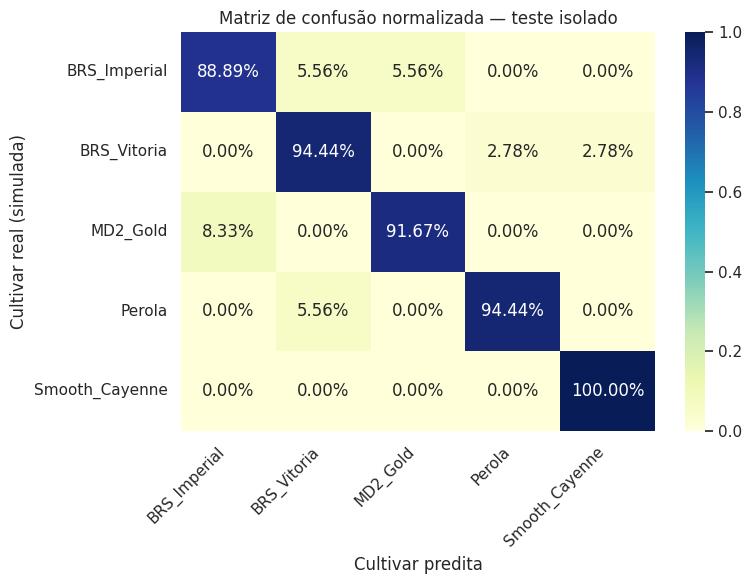

Matriz calculada sobre 180 amostras do teste original.


In [120]:
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from scripts.train_pipeline import NUMERIC_FEATURES, CATEGORICAL_FEATURES

# Reutiliza exatamente as amostras isoladas no treinamento; mantém os nulos.
df_ananas = pd.read_csv("data/ananas_comosus_cultivares.csv")
indices_teste = json.loads(open("models/test_indices.json", encoding="utf-8").read())
X_test = df_ananas.loc[indices_teste, NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y_test = df_ananas.loc[indices_teste, "cultivar"]
pipeline = joblib.load("models/pipeline_ananas_v1.joblib")
y_pred = pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=pipeline.classes_, normalize="true")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=".2%", cmap="YlGnBu",
            xticklabels=pipeline.classes_, yticklabels=pipeline.classes_)
plt.title("Matriz de confusão normalizada — teste isolado")
plt.xlabel("Cultivar predita")
plt.ylabel("Cultivar real (simulada)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("models/confusion_matrix.png", dpi=150)
plt.show()
print(f"Matriz calculada sobre {len(X_test)} amostras do teste original.")


## Etapa 4 (Fase 4): Modelagem e Validação Estrita com Pydantic (`app/schemas.py`)
Define os esquemas de entrada e saída com `BaseModel` e `Field`, assegurando que valores fora dos limites agronômicos ou com tipos inválidos retornem `422 Unprocessable Entity`.

In [121]:
%%writefile app/schemas.py
"""
Fase 4: Modelagem e Validacao Estrita de Dados com Pydantic.
"""

from typing import Dict, Literal
from pydantic import BaseModel, Field, ConfigDict, field_validator


class AmostraAbacaxiInput(BaseModel):
    @field_validator("massa_fruto_g", "comprimento_fruto_cm", "diametro_fruto_cm",
                     "diametro_cilindro_mm", "brix_sst", "acidez_titulavel_pct",
                     "firmeza_polpa_n", mode="before")
    @classmethod
    def exigir_numero_json(cls, value):
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError("O campo deve ser numérico, sem conversão de texto")
        return value

    massa_fruto_g: float = Field(..., ge=400.0, le=4500.0, description="Massa do fruto sem coroa (g)")
    comprimento_fruto_cm: float = Field(..., ge=8.0, le=35.0, description="Comprimento do fruto (cm)")
    diametro_fruto_cm: float = Field(..., ge=6.0, le=22.0, description="Diametro equatorial do fruto (cm)")
    diametro_cilindro_mm: float = Field(..., gt=5.0, le=50.0, description="Diametro do cilindro central (mm)")
    brix_sst: float = Field(..., ge=8.0, le=25.0, description="Solidos Soluveis Totais (graus Brix)")
    acidez_titulavel_pct: float = Field(..., gt=0.10, le=2.00, description="Acidez Titulavel (% acido citrico)")
    firmeza_polpa_n: float = Field(..., ge=5.0, le=40.0, description="Firmeza da polpa (Newtons)")
    cor_polpa: Literal["branca", "amarelo_palido", "amarela", "amarelo_ouro"] = Field(...)
    presenca_espinhos: Literal["presente", "ausente"] = Field(...)
    formato_fruto: Literal["conico", "cilindrico"] = Field(...)

    model_config = ConfigDict(
        extra="forbid",
        json_schema_extra={
            "example": {
                "massa_fruto_g": 1480.0,
                "comprimento_fruto_cm": 16.2,
                "diametro_fruto_cm": 12.1,
                "diametro_cilindro_mm": 18.5,
                "brix_sst": 17.6,
                "acidez_titulavel_pct": 0.52,
                "firmeza_polpa_n": 20.5,
                "cor_polpa": "amarelo_ouro",
                "presenca_espinhos": "ausente",
                "formato_fruto": "cilindrico",
            }
        }
    )


class PredicaoCultivarOutput(BaseModel):
    cultivar_predita: str
    confianca_predicao: float = Field(..., ge=0.0, le=1.0)
    probabilidades_classes: Dict[str, float]
    ratio_brix_acidez: float
    aptidao_recomendada: str
    resistencia_fusariose: str
    versao_modelo: str = Field(default="1.0.0")


class HealthCheckOutput(BaseModel):
    status: str
    model_loaded: bool = Field(description="Indica se o modelo está carregado")
    artifact_path: str
    supported_cultivars: list[str]

Overwriting app/schemas.py


## Etapa 5 (Fase 2): Camada de Serviço e Regras de Negócio (`app/services.py`)
Isola o carregamento do modelo `.joblib` e a execução da inferência matemática do protocolo HTTP.

In [122]:
%%writefile app/services.py
"""
Fase 2: Camada de Servico e Regras de Negocio Agronomicas (services.py).
"""

from pathlib import Path
from typing import Dict
import pandas as pd
import joblib

from app.schemas import AmostraAbacaxiInput, PredicaoCultivarOutput

CATALOGO_AGRONOMICO: Dict[str, Dict[str, str]] = {
    "Perola": {
        "aptidao": "Consumo In Natura (Mercado Interno - Preferencia Nacional)",
        "fusariose": "Suscetivel (requer manejo fitossanitario rigoroso)",
    },
    "Smooth_Cayenne": {
        "aptidao": "Dupla Aptidao (Processamento Industrial de Suco/Calda e Mesa)",
        "fusariose": "Suscetivel",
    },
    "BRS_Imperial": {
        "aptidao": "Mesa Premium e Exportacao (Elevado Ratio SST/AT e polpa amarelo-ouro)",
        "fusariose": "Resistente a Fusarium guttiforme",
    },
    "BRS_Vitoria": {
        "aptidao": "Mesa In Natura e Processamento Leve (Folhas sem espinhos)",
        "fusariose": "Resistente a Fusarium guttiforme",
    },
    "MD2_Gold": {
        "aptidao": "Exportacao In Natura (Alta firmeza de polpa e vida util pos-colheita)",
        "fusariose": "Moderadamente Suscetivel",
    },
}


class DomainValidationError(ValueError):
    pass


class AnanasClassifierService:
    def __init__(self, model_path: Path) -> None:
        self.model_path = model_path
        self.pipeline = None
        self.versao_modelo = "1.0.0"

    def load_model(self) -> None:
        if not self.model_path.exists():
            raise FileNotFoundError(f"Artefato nao encontrado em {self.model_path}")
        # Carregar somente artefatos gerados pelo próprio projeto (joblib usa pickle).
        self.pipeline = joblib.load(self.model_path)

    def unload_model(self) -> None:
        self.pipeline = None

    @property
    def is_ready(self) -> bool:
        return self.pipeline is not None

    def get_classes(self) -> list[str]:
        if not self.is_ready:
            return []
        return [str(c) for c in self.pipeline.classes_]

    def _validate_biophysical_consistency(self, payload: AmostraAbacaxiInput) -> None:
        diametro_fruto_mm = payload.diametro_fruto_cm * 10.0
        # Regra didática de plausibilidade, NÃO um limiar agronômico oficial.
        if payload.diametro_cilindro_mm >= (diametro_fruto_mm * 0.65):
            raise DomainValidationError(
                f"Inconsistencia morfometrica: diametro do cilindro central ({payload.diametro_cilindro_mm} mm) "
                f"excede 65% do diametro total do fruto ({diametro_fruto_mm:.1f} mm)."
            )

    def predict(self, payload: AmostraAbacaxiInput) -> PredicaoCultivarOutput:
        if not self.is_ready:
            raise RuntimeError("O pipeline preditivo nao esta carregado em memoria.")

        self._validate_biophysical_consistency(payload)

        input_df = pd.DataFrame([payload.model_dump()])
        probs = self.pipeline.predict_proba(input_df)[0]
        classes = self.pipeline.classes_

        prob_dict = {str(cls): round(float(prob), 4) for cls, prob in zip(classes, probs)}
        best_idx = int(probs.argmax())
        cultivar_predita = str(classes[best_idx])
        confianca = round(float(probs[best_idx]), 4)

        ratio_sst_at = round(payload.brix_sst / payload.acidez_titulavel_pct, 2)
        info_catalogo = CATALOGO_AGRONOMICO.get(
            cultivar_predita, {"aptidao": "Uso Geral", "fusariose": "Nao especificado"}
        )

        return PredicaoCultivarOutput(
            cultivar_predita=cultivar_predita,
            confianca_predicao=confianca,
            probabilidades_classes=prob_dict,
            ratio_brix_acidez=ratio_sst_at,
            aptidao_recomendada=info_catalogo["aptidao"],
            resistencia_fusariose=info_catalogo["fusariose"],
            versao_modelo=self.versao_modelo,
        )

Overwriting app/services.py


## Etapa 6 (Fase 5): Implementação de Endpoints e Tratamento de Erros (`app/routers.py`)
Cria os endpoints `GET /health` e `POST /v1/predict` (e `/predict`) com tratamento semântico de erros HTTP (`200`, `400`, `422`, `500`).

In [123]:
%%writefile app/routers.py
"""
Fase 2 e Fase 5: Implementacao de Rotas e Tratamento de Excecoes HTTP (routers.py).
"""

import logging
from fastapi import APIRouter, HTTPException, Request, status
from app.schemas import AmostraAbacaxiInput, PredicaoCultivarOutput, HealthCheckOutput
from app.services import AnanasClassifierService, DomainValidationError

logger = logging.getLogger(__name__)
router = APIRouter()


def _get_ml_service(request: Request) -> AnanasClassifierService:
    service: AnanasClassifierService | None = getattr(request.app.state, "ml_service", None)
    if service is None or not service.is_ready:
        raise HTTPException(
            status_code=status.HTTP_503_SERVICE_UNAVAILABLE,
            detail="Modelo preditivo indisponivel em memoria RAM.",
        )
    return service


@router.get(
    "/health",
    response_model=HealthCheckOutput,
    status_code=status.HTTP_200_OK,
    tags=["Monitoramento"],
)
async def health_check(request: Request) -> HealthCheckOutput:
    service: AnanasClassifierService | None = getattr(request.app.state, "ml_service", None)
    is_loaded = bool(service and service.is_ready)
    return HealthCheckOutput(
        status="healthy" if is_loaded else "degraded",
        model_loaded=is_loaded,
        artifact_path="models/pipeline_ananas_v1.joblib",
        supported_cultivars=service.get_classes() if is_loaded else [],
    )


@router.post(
    "/v1/predict",
    response_model=PredicaoCultivarOutput,
    status_code=status.HTTP_200_OK,
    tags=["Inferencia Agronomica"],
)
@router.post(
    "/predict",
    response_model=PredicaoCultivarOutput,
    status_code=status.HTTP_200_OK,
    tags=["Inferencia Agronomica"],
)
async def predict_cultivar(payload: AmostraAbacaxiInput, request: Request) -> PredicaoCultivarOutput:
    service = _get_ml_service(request)
    try:
        return service.predict(payload)
    except DomainValidationError as exc:
        raise HTTPException(status_code=status.HTTP_400_BAD_REQUEST, detail=str(exc)) from exc
    except RuntimeError as exc:
        raise HTTPException(status_code=503, detail="Modelo preditivo indisponível.") from exc
    except Exception as exc:
        logger.exception("Erro inesperado durante a inferência")
        raise HTTPException(
            status_code=status.HTTP_500_INTERNAL_SERVER_ERROR,
            detail="Falha interna durante o processamento da inferência.",
        ) from exc

Overwriting app/routers.py


## Etapa 7 (Fase 3): Ponto de Entrada e Ciclo de Vida Lifespan (`app/main.py`)
Carrega o modelo `.joblib` na memória RAM uma única vez na inicialização da API via `@asynccontextmanager` (`lifespan`).

In [124]:
%%writefile app/main.py
"""
Fase 2 e Fase 3: Ponto de Entrada da Aplicacao e Gerenciamento de Ciclo de Vida (main.py).
"""

from contextlib import asynccontextmanager
from pathlib import Path
import logging
from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import RedirectResponse
from app.routers import router
from app.services import AnanasClassifierService

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("ananas_api")

BASE_DIR = Path(__file__).resolve().parent.parent
MODEL_PATH = BASE_DIR / "models" / "pipeline_ananas_v1.joblib"


@asynccontextmanager
async def lifespan(app: FastAPI):
    logger.info("Carregando artefato preditivo em memoria RAM...")
    ml_service = AnanasClassifierService(model_path=MODEL_PATH)
    ml_service.load_model()
    app.state.ml_service = ml_service
    try:
        yield
    finally:
        logger.info("Encerrando serviço e liberando memória...")
        ml_service.unload_model()


app = FastAPI(
    title="API de Classificacao Morfoagronomica de Abacaxi (Ananas comosus)",
    version="1.0.0",
    lifespan=lifespan,
)


# A documentação Swagger, servida na mesma origem, não depende de CORS.
import os
origins = [v.strip() for v in os.getenv("ANANAS_CORS_ORIGINS", "").split(",") if v.strip()]
if origins:
    app.add_middleware(
        CORSMiddleware,
        allow_origins=origins,
        allow_credentials=False,
        allow_methods=["GET", "POST"],
        allow_headers=["Content-Type"],
    )

app.include_router(router)

# Redirecionamento da raiz para a documentação interativa.
@app.get("/", include_in_schema=False)
async def root_redirect():
    """Redireciona acessos à raiz da API direto para a documentação interativa."""
    return RedirectResponse(url="/docs")


Overwriting app/main.py


## Etapa 8: Bateria de Testes dos Endpoints dentro do Google Colab
Utiliza o `TestClient` oficial do FastAPI para acionar o ciclo de vida (`lifespan`) e testar os 4 cenários exigidos na avaliação: `GET /health` (200), `POST /v1/predict` válido (200), `POST /v1/predict` com tipo/limite inválido (422) e `POST /v1/predict` com inconsistência anatômica (400).

In [125]:
import json
from fastapi.testclient import TestClient
from app.main import app

with TestClient(app) as client:
    print("1. TESTE GET /health (Status Esperado: 200 OK)")
    res_health = client.get("/health")
    print("Status Code:", res_health.status_code)
    print(json.dumps(res_health.json(), indent=2, ensure_ascii=False))

    print("\n" + "="*60)
    print("2. TESTE POST /v1/predict VALIDO (Status Esperado: 200 OK)")
    payload_valido = {
        "massa_fruto_g": 1480.0,
        "comprimento_fruto_cm": 16.2,
        "diametro_fruto_cm": 12.1,
        "diametro_cilindro_mm": 18.5,
        "brix_sst": 17.6,
        "acidez_titulavel_pct": 0.52,
        "firmeza_polpa_n": 20.5,
        "cor_polpa": "amarelo_ouro",
        "presenca_espinhos": "ausente",
        "formato_fruto": "cilindrico"
    }
    res_pred = client.post("/v1/predict", json=payload_valido)
    print("Status Code:", res_pred.status_code)
    print(json.dumps(res_pred.json(), indent=2, ensure_ascii=False))

    print("\n" + "="*60)
    print("3. TESTE POST /v1/predict DADO INVALIDO - PYDANTIC (Status Esperado: 422)")
    payload_invalido_422 = payload_valido.copy()
    payload_invalido_422["brix_sst"] = 55.0  # Acima do limite maximo de 25.0 graus Brix
    res_422 = client.post("/v1/predict", json=payload_invalido_422)
    print("Status Code:", res_422.status_code)
    print(json.dumps(res_422.json(), indent=2, ensure_ascii=False))

    print("\n" + "="*60)
    print("4. TESTE POST /v1/predict INCONSISTENCIA BIOFISICA (Status Esperado: 400)")
    payload_inconsistente_400 = payload_valido.copy()
    payload_inconsistente_400["diametro_fruto_cm"] = 6.5
    payload_inconsistente_400["diametro_cilindro_mm"] = 48.0  # Cilindro maior que 65% do diametro do fruto
    res_400 = client.post("/v1/predict", json=payload_inconsistente_400)
    print("Status Code:", res_400.status_code)
    print(json.dumps(res_400.json(), indent=2, ensure_ascii=False))

1. TESTE GET /health (Status Esperado: 200 OK)
Status Code: 200
{
  "status": "healthy",
  "model_loaded": true,
  "artifact_path": "models/pipeline_ananas_v1.joblib",
  "supported_cultivars": [
    "BRS_Imperial",
    "BRS_Vitoria",
    "MD2_Gold",
    "Perola",
    "Smooth_Cayenne"
  ]
}

2. TESTE POST /v1/predict VALIDO (Status Esperado: 200 OK)
Status Code: 200
{
  "cultivar_predita": "BRS_Imperial",
  "confianca_predicao": 0.9817,
  "probabilidades_classes": {
    "BRS_Imperial": 0.9817,
    "BRS_Vitoria": 0.0,
    "MD2_Gold": 0.0183,
    "Perola": 0.0,
    "Smooth_Cayenne": 0.0
  },
  "ratio_brix_acidez": 33.85,
  "aptidao_recomendada": "Mesa Premium e Exportacao (Elevado Ratio SST/AT e polpa amarelo-ouro)",
  "resistencia_fusariose": "Resistente a Fusarium guttiforme",
  "versao_modelo": "1.0.0"
}

3. TESTE POST /v1/predict DADO INVALIDO - PYDANTIC (Status Esperado: 422)
Status Code: 422
{
  "detail": [
    {
      "type": "less_than_equal",
      "loc": [
        "body",
      

## Etapa 9 — Documentação, dependências e empacotamento

O README apresenta instalação, execução, exemplo de requisição, limites científicos e os passos para publicar no GitHub. O pacote final inclui também testes automatizados.


In [126]:
# As dependências já foram criadas e instaladas na Etapa 1.
from pathlib import Path
print(Path("requirements.txt").read_text(encoding="utf-8"))


fastapi>=0.115,<1
uvicorn>=0.30,<1
pydantic>=2.9,<3
scikit-learn>=1.5,<2
pandas>=2.2,<3
numpy>=1.26,<3
joblib>=1.4,<2
httpx>=0.27,<1
matplotlib>=3.8,<4
seaborn>=0.13,<1



In [127]:
from pathlib import Path
Path("README.md").write_text('# Projeto Ananas — classificação morfoagronômica (demonstração)\n\nAPI FastAPI para classificar cinco cultivares de abacaxi com um pipeline scikit-learn treinado em **dados sintéticos**. Não é um diagnóstico agronômico validado.\n\n## Estrutura\n- `data/`: base sintética, proveniência e previsões em lote.\n- `scripts/train_pipeline.py`: preparação, treinamento e avaliação com divisão estratificada 70/15/15.\n- `models/`: pipeline, métricas, índices do teste isolado e matriz de confusão.\n- `app/schemas.py`: validação Pydantic.\n- `app/services.py`: inferência e catálogo ilustrativo.\n- `app/routers.py`: endpoints e tratamento de erros.\n- `app/main.py`: carregamento via lifespan, CORS configurável e redirecionamento da raiz.\n- `tests/test_api.py`: testes HTTP e validação.\n\n## Execução local\n```bash\npython -m pip install -r requirements.txt\npython scripts/train_pipeline.py\npython -m unittest discover -s tests -v\npython -m uvicorn app.main:app --host 127.0.0.1 --port 8000\n```\nAcesse `http://127.0.0.1:8000/docs`. No Colab, execute as células em ordem; o proxy do Colab permite abrir o Swagger no navegador.\n\n## Exemplo de requisição\n`POST /v1/predict` (também disponível em `/predict`):\n```json\n{"massa_fruto_g":1480,"comprimento_fruto_cm":16.2,"diametro_fruto_cm":12.1,"diametro_cilindro_mm":18.5,"brix_sst":17.6,"acidez_titulavel_pct":0.52,"firmeza_polpa_n":20.5,"cor_polpa":"amarelo_ouro","presenca_espinhos":"ausente","formato_fruto":"cilindrico"}\n```\n`GET /health`: 200 com status do modelo. `POST`: 200 sucesso, 422 entrada inválida, 400 inconsistência morfométrica didática, 503 modelo indisponível e 500 erro inesperado. A regra de 65% é apenas heurística de demonstração, sem validação agronômica.\n\n## Avaliação e limites\nHiperparâmetros fixados antes do teste; a validação é diagnóstica, não uma busca de parâmetros. O conjunto de teste isolado tem índices persistidos em `models/test_indices.json`, reutilizados na matriz de confusão sem excluir ausentes. As probabilidades não são calibradas e não expressam confiança em campo. Métricas são válidas apenas para a distribuição simulada. Consulte `data/proveniencia_base.md`.\n\n## Segurança e ambiente\nSomente carregue `.joblib` produzido por fonte confiável. CORS fica desativado por padrão; para permitir um frontend específico, configure `ANANAS_CORS_ORIGINS=https://exemplo.com` antes de iniciar a API. Versões de dependências têm faixas compatíveis para Colab; o ambiente deve ser registrado em entregas reprodutíveis.\n\n## Entrega\nO ZIP final inclui código, dados sintéticos, testes, métricas, gráficos e relatório, gerados após todas as etapas. Acrescente links de vídeo e repositório somente após a publicação, sem usar links fictícios.\n', encoding="utf-8")
Path("tests").mkdir(exist_ok=True)
Path("tests/test_api.py").write_text(r'''import unittest
from unittest.mock import patch
from fastapi.testclient import TestClient
from app.main import app

VALIDO = {
    "massa_fruto_g": 1480.0, "comprimento_fruto_cm": 16.2,
    "diametro_fruto_cm": 12.1, "diametro_cilindro_mm": 18.5,
    "brix_sst": 17.6, "acidez_titulavel_pct": 0.52,
    "firmeza_polpa_n": 20.5, "cor_polpa": "amarelo_ouro",
    "presenca_espinhos": "ausente", "formato_fruto": "cilindrico",
}

class TestAPI(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        cls.manager = TestClient(app)
        cls.client = cls.manager.__enter__()

    @classmethod
    def tearDownClass(cls):
        cls.manager.__exit__(None, None, None)

    def test_health(self):
        r = self.client.get("/health")
        self.assertEqual(r.status_code, 200)
        self.assertTrue(r.json()["model_loaded"])

    def test_predict_and_probabilities(self):
        r = self.client.post("/v1/predict", json=VALIDO)
        self.assertEqual(r.status_code, 200)
        data = r.json()
        self.assertIn(data["cultivar_predita"], data["probabilidades_classes"])
        self.assertAlmostEqual(sum(data["probabilidades_classes"].values()), 1, delta=0.001)
        self.assertAlmostEqual(data["confianca_predicao"], max(data["probabilidades_classes"].values()))

    def test_predict_alias(self):
        self.assertEqual(self.client.post("/predict", json=VALIDO).status_code, 200)

    def test_missing_required_field(self):
        invalid = dict(VALIDO)
        del invalid["massa_fruto_g"]
        self.assertEqual(self.client.post("/v1/predict", json=invalid).status_code, 422)

    def test_unknown_category(self):
        self.assertEqual(self.client.post("/v1/predict", json=dict(VALIDO, cor_polpa="roxa")).status_code, 422)

    def test_invalid_numeric_type(self):
        self.assertEqual(self.client.post("/v1/predict", json=dict(VALIDO, brix_sst="17.6")).status_code, 422)

    def test_numeric_bounds(self):
        for field, value in [("brix_sst", 25.1), ("massa_fruto_g", 399), ("acidez_titulavel_pct", 0.1)]:
            with self.subTest(field=field):
                self.assertEqual(self.client.post("/v1/predict", json=dict(VALIDO, **{field: value})).status_code, 422)

    def test_extra_field(self):
        self.assertEqual(self.client.post("/v1/predict", json=dict(VALIDO, origem="teste")).status_code, 422)

    def test_domain_consistency(self):
        invalid = dict(VALIDO, diametro_fruto_cm=6.5, diametro_cilindro_mm=48.0)
        self.assertEqual(self.client.post("/v1/predict", json=invalid).status_code, 400)

    def test_unavailable_service(self):
        service = app.state.ml_service
        with patch.object(service, "pipeline", None):
            self.assertEqual(self.client.post("/v1/predict", json=VALIDO).status_code, 503)

    def test_root_redirect(self):
        self.assertEqual(self.client.get("/", follow_redirects=False).status_code, 307)

if __name__ == "__main__":
    unittest.main()
''', encoding="utf-8")
print("README e testes criados")


README e testes criados


In [128]:
!python -m unittest discover -s tests -v


2026-11-08 23:16:04,104 | INFO | Carregando artefato preditivo em memoria RAM...
test_domain_consistency (test_api.TestAPI.test_domain_consistency) ... 2026-11-08 23:16:07,470 | INFO | HTTP Request: POST http://testserver/v1/predict "HTTP/1.1 400 Bad Request"
ok
test_extra_field (test_api.TestAPI.test_extra_field) ... 2026-11-08 23:16:07,478 | INFO | HTTP Request: POST http://testserver/v1/predict "HTTP/1.1 422 Unprocessable Content"
ok
test_health (test_api.TestAPI.test_health) ... 2026-11-08 23:16:07,487 | INFO | HTTP Request: GET http://testserver/health "HTTP/1.1 200 OK"
ok
test_invalid_numeric_type (test_api.TestAPI.test_invalid_numeric_type) ... 2026-11-08 23:16:07,498 | INFO | HTTP Request: POST http://testserver/v1/predict "HTTP/1.1 422 Unprocessable Content"
ok
test_missing_required_field (test_api.TestAPI.test_missing_required_field) ... 2026-11-08 23:16:07,506 | INFO | HTTP Request: POST http://testserver/v1/predict "HTTP/1.1 422 Unprocessable Content"
ok
test_numeric_bounds

In [129]:
import subprocess
import sys
import time
import urllib.request
from pathlib import Path
from IPython.display import HTML, display

PORTA = 8000
LOG_PATH = Path("/tmp/ananas_uvicorn.log")

# Encerra somente o processo iniciado por este notebook, se ainda existir.
if "servidor_ananas" in globals() and servidor_ananas.poll() is None:
    servidor_ananas.terminate()
    try:
        servidor_ananas.wait(timeout=5)
    except subprocess.TimeoutExpired:
        servidor_ananas.kill()
        servidor_ananas.wait()

arquivo_log = LOG_PATH.open("w", encoding="utf-8")
servidor_ananas = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "app.main:app", "--host", "127.0.0.1", "--port", str(PORTA)],
    stdout=arquivo_log, stderr=subprocess.STDOUT,
)
arquivo_log.close()

for _ in range(30):
    if servidor_ananas.poll() is not None:
        raise RuntimeError(f"Servidor encerrou. Consulte {LOG_PATH}")
    try:
        with urllib.request.urlopen(f"http://127.0.0.1:{PORTA}/health", timeout=2) as resposta:
            if resposta.status == 200:
                break
    except (OSError, TimeoutError):
        time.sleep(1)
else:
    raise RuntimeError(f"Servidor não respondeu. Consulte {LOG_PATH}")

try:
    from google.colab import output
    proxy = output.eval_js(f"google.colab.kernel.proxyPort({PORTA})").rstrip("/")
    display(HTML(f'<a href="{proxy}/docs" target="_blank">Abrir Swagger no navegador</a>'))
except ImportError:
    print(f"Swagger local: http://127.0.0.1:{PORTA}/docs")
print("API pronta; log:", LOG_PATH)


API pronta; log: /tmp/ananas_uvicorn.log


## Etapa 10: Automação do Relatório Final

Este script lê o artefato JSON de métricas gerado pelo pipeline de treinamento e constrói um relatório Markdown formatado automaticamente. Isso evita a cópia manual de resultados.

In [130]:
import json
from pathlib import Path
from IPython.display import display, Markdown

# 1. Carregar as métricas geradas pelo pipeline
caminho_metricas = Path("models/metrics_report.json")
with open(caminho_metricas, "r", encoding="utf-8") as f:
    metrics = json.load(f)

# 2. Criar o template do relatório final automatizado
conteudo_relatorio = f"""# Relatório Final de Modelagem - Cultivares de Abacaxi

Este relatório foi gerado automaticamente a partir do último treinamento do modelo.

## 1. Informações do Modelo
- **Algoritmo:** `{metrics['algorithm']}`
- **Versão:** `{metrics['model_version']}`
- **Limitação Científica:** {metrics['scientific_limitation']}

## 2. Divisão do Conjunto de Dados
- **Treino:** {metrics['dataset_splits']['train_samples']} amostras
- **Validação:** {metrics['dataset_splits']['validation_samples']} amostras
- **Teste:** {metrics['dataset_splits']['test_samples']} amostras

## 3. Desempenho (Conjunto de Teste Isolado)
- **Acurácia (Accuracy):** {metrics['test_metrics']['accuracy'] * 100:.2f}%
- **F1-Score (Macro):** {metrics['test_metrics']['f1_macro'] * 100:.2f}%
- **Área Sob a Curva ROC (ROC-AUC OVR):** {metrics['test_metrics']['roc_auc_ovr'] * 100:.2f}%

## 4. Interpretação e rastreabilidade
- **Escolha do modelo:** hiperparâmetros fixados previamente, sem ajuste automático.
- **Probabilidades:** não calibradas; não representam confiança em dados de campo.
- **Matriz de confusão:** utiliza os mesmos índices do conjunto de teste isolado.
- **Base:** dados sintéticos com parâmetros manuais; consulte `data/proveniencia_base.md`.

## 5. Classes Suportadas pela API
{', '.join(metrics['classes'])}
"""

# 3. Salvar o conteúdo em um arquivo Markdown
caminho_relatorio = Path("relatorio_final.md")
caminho_relatorio.write_text(conteudo_relatorio, encoding="utf-8")

print(f"✅ Relatório final automatizado gerado com sucesso em: {caminho_relatorio}")

# Exibe uma prévia do que foi salvo:
display(Markdown("---\n**Prévia do Relatório Gerado:**\n\n" + conteudo_relatorio))

✅ Relatório final automatizado gerado com sucesso em: relatorio_final.md


---
**Prévia do Relatório Gerado:**

# Relatório Final de Modelagem - Cultivares de Abacaxi

Este relatório foi gerado automaticamente a partir do último treinamento do modelo.

## 1. Informações do Modelo
- **Algoritmo:** `RandomForestClassifier`
- **Versão:** `1.0.0`
- **Limitação Científica:** Métricas sobre dados simulados; não validado em campo.

## 2. Divisão do Conjunto de Dados
- **Treino:** 840 amostras
- **Validação:** 180 amostras
- **Teste:** 180 amostras

## 3. Desempenho (Conjunto de Teste Isolado)
- **Acurácia (Accuracy):** 93.89%
- **F1-Score (Macro):** 93.88%
- **Área Sob a Curva ROC (ROC-AUC OVR):** 99.58%

## 4. Interpretação e rastreabilidade
- **Escolha do modelo:** hiperparâmetros fixados previamente, sem ajuste automático.
- **Probabilidades:** não calibradas; não representam confiança em dados de campo.
- **Matriz de confusão:** utiliza os mesmos índices do conjunto de teste isolado.
- **Base:** dados sintéticos com parâmetros manuais; consulte `data/proveniencia_base.md`.

## 5. Classes Suportadas pela API
BRS_Imperial, BRS_Vitoria, MD2_Gold, Perola, Smooth_Cayenne


## Etapa 11 — Conferência do redirecionamento `/`

A raiz já está configurada no `app/main.py` antes da inicialização. Verificamos o redirecionamento sem encerrar ou reiniciar o servidor, evitando conflitos de porta no Colab.


In [131]:
import urllib.request

url = f"http://127.0.0.1:{PORTA}/"
class SemRedirecionamento(urllib.request.HTTPRedirectHandler):
    def redirect_request(self, req, fp, code, msg, headers, newurl):
        return None

try:
    urllib.request.build_opener(SemRedirecionamento()).open(url)
except urllib.error.HTTPError as exc:
    assert exc.code == 307 and exc.headers.get("Location") == "/docs"
    print("Redirecionamento / → /docs confirmado (HTTP 307).")


Redirecionamento / → /docs confirmado (HTTP 307).


## Etapa 12: Automação para Novos Dados (Processamento em Lote / Batch)

Além da API (que prevê um item por vez em tempo real), este script demonstra como automatizar previsões para uma grande quantidade de novos dados inseridos via planilha/CSV.

In [132]:
import joblib
import pandas as pd
from pathlib import Path
from IPython.display import display

print("1. Carregando o modelo treinado...")
pipeline = joblib.load("models/pipeline_ananas_v1.joblib")

print("2. Simulando a chegada de 'novos dados' (poderia ser pd.read_csv('novos_abacaxis.csv'))...")
novos_dados = pd.DataFrame([
    {
        "massa_fruto_g": 1650.0, "comprimento_fruto_cm": 17.5, "diametro_fruto_cm": 12.8,
        "diametro_cilindro_mm": 21.0, "brix_sst": 18.2, "acidez_titulavel_pct": 0.49,
        "firmeza_polpa_n": 21.0, "cor_polpa": "amarelo_ouro", "presenca_espinhos": "ausente",
        "formato_fruto": "cilindrico"
    },
    {
        "massa_fruto_g": 1350.0, "comprimento_fruto_cm": 19.5, "diametro_fruto_cm": 11.2,
        "diametro_cilindro_mm": 24.0, "brix_sst": 14.1, "acidez_titulavel_pct": 0.40,
        "firmeza_polpa_n": 16.0, "cor_polpa": "branca", "presenca_espinhos": "presente",
        "formato_fruto": "conico"
    }
])

print("3. Automatizando as previsões...")
# O pipeline cuida automaticamente do pré-processamento (imputação, escalonamento, OneHotEncoding)
predicoes = pipeline.predict(novos_dados)

# Anexando as predições aos dados originais
novos_dados['cultivar_predita'] = predicoes

print("4. Salvando os resultados automatizados...")
caminho_resultado = Path("data/previsoes_lote_resultado.csv")
novos_dados.to_csv(caminho_resultado, index=False)

print(f"✅ Processamento concluído! Resultados salvos em: {caminho_resultado}\n")
display(novos_dados)

1. Carregando o modelo treinado...
2. Simulando a chegada de 'novos dados' (poderia ser pd.read_csv('novos_abacaxis.csv'))...
3. Automatizando as previsões...
4. Salvando os resultados automatizados...
✅ Processamento concluído! Resultados salvos em: data/previsoes_lote_resultado.csv



,massa_fruto_g,comprimento_fruto_cm,diametro_fruto_cm,diametro_cilindro_mm,brix_sst,acidez_titulavel_pct,firmeza_polpa_n,cor_polpa,presenca_espinhos,formato_fruto,cultivar_predita
0,1650.0,17.5,12.8,21.0,18.2,0.49,21.0,amarelo_ouro,ausente,cilindrico,BRS_Imperial
1,1350.0,19.5,11.2,24.0,14.1,0.40,16.0,branca,presente,conico,Perola


## Etapa 13 — Empacotamento final

Execute somente após concluir o relatório e o processamento em lote. Todos os artefatos obrigatórios são verificados.


In [133]:
import zipfile
from pathlib import Path

arquivos_projeto = [
    "requirements.txt", "README.md", "tests/test_api.py",
    "data/ananas_comosus_cultivares.csv", "data/proveniencia_base.md",
    "data/previsoes_lote_resultado.csv", "scripts/train_pipeline.py",
    "models/pipeline_ananas_v1.joblib", "models/metrics_report.json",
    "models/test_indices.json", "models/confusion_matrix.png",
    "app/__init__.py", "app/schemas.py", "app/services.py",
    "app/routers.py", "app/main.py", "relatorio_final.md",
]
ausentes = [nome for nome in arquivos_projeto if not Path(nome).is_file()]
if ausentes:
    raise FileNotFoundError(f"Execute as etapas anteriores; faltam: {ausentes}")
zip_path = Path("projeto_ananas_colab.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as pacote:
    for nome in arquivos_projeto:
        pacote.write(nome)
print(f"Pacote final: {zip_path} ({len(arquivos_projeto)} arquivos)")
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Execução local: ZIP disponível no diretório atual.")


Pacote final: projeto_ananas_colab.zip (17 arquivos)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>